In [1]:
from visualize import *
from data_generation import *   
from preprocessing import *
from sb import loss
from sb import model
from datasets.dataset import *
from torch.utils.data import DataLoader

In [2]:
high_resol_coef = 0.01 # 점성 계수 작게
low_resol_coef = 0.1 # 점성 계수 크게

high_f_1d = generate_dataset(nu=high_resol_coef, Nx=512, Nt=512, T=1.0, L=1.0, seed=0, warmup_steps=100)
print("GT high PDE (before downsampling) :", loss.burgers_residual(torch.tensor(high_f_1d), high_resol_coef))
high_f_1d = high_f_1d[:,:,::4,::4]
low_f_1d = generate_dataset(nu=low_resol_coef, Nx=128, Nt=128, T=1.0, L=1.0, U0=high_f_1d[:,:,[0], :], seed=20)
print("GT low PDE (after downsampling) :", loss.burgers_residual(torch.tensor(low_f_1d), low_resol_coef), "GT high PDE (after downsampling) :", loss.burgers_residual(torch.tensor(high_f_1d), high_resol_coef))
low_f_1d, high_f_1d = make_paired_time_window_dataset(low_f_1d, high_f_1d, win_T=128, stride=128)
print("GT low PDE (after downsampling) :", loss.burgers_residual(torch.tensor(low_f_1d), low_resol_coef), "GT high PDE (after downsampling) :", loss.burgers_residual(torch.tensor(high_f_1d), high_resol_coef))
mask_low_1d = make_sensor_mask(low_f_1d, n_sensors=13, sparse_ratio=None, seed=0)
mask_high_1d = make_sensor_mask(high_f_1d, n_sensors=13, sparse_ratio=None, seed=0)

# dataset_visualization(low_f_1d, mask_low_1d, batch_idx=0)
# dataset_visualization(high_f_1d, mask_high_1d, batch_idx=0)

100%|██████████| 1/1 [00:00<00:00, 24.88it/s]


GT high PDE (before downsampling) : tensor(1.4020e-07)


100%|██████████| 1/1 [00:00<00:00, 147.83it/s]

GT low PDE (after downsampling) : tensor(0.0001) GT high PDE (after downsampling) : tensor(8.6722e-06)
GT low PDE (after downsampling) : tensor(0.0001) GT high PDE (after downsampling) : tensor(8.6722e-06)



/tmp/ipykernel_2051130/4265610072.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  print("GT low PDE (after downsampling) :", loss.burgers_residual(torch.tensor(low_f_1d), low_resol_coef), "GT high PDE (after downsampling) :", loss.burgers_residual(torch.tensor(high_f_1d), high_resol_coef))


In [3]:
# # 코드 작성을 위해 임의로 만든 샘플 데이터임. 추후 시뮬 데이터로 교체 예정
# high = np.load("./data_test/NS-Re1000_T255.npy", mmap_mode="r")
# high_f_2d = np.concatenate([high] * 10, axis=0)

# low = np.load("./data_test/NS-Re1000_T255.npy", mmap_mode="r")
# low_f_2d = np.concatenate([low] * 10, axis=0)

# mask_high_2d = make_sensor_mask(high_f_2d, n_sensors=int(256*256*0.1), sparse_ratio=None, seed=0)
# mask_low_2d = make_sensor_mask(low_f_2d, n_sensors=int(256*256*0.1), sparse_ratio=None, seed=0)

# ds_2d = PDEPairDataset(low_f_2d, high_f_2d, None, mask_high_2d)
# dl_2d = DataLoader(ds_2d, batch_size=2, shuffle=True, drop_last=False)

In [4]:
N = low_f_1d.shape[0]
train_ratio = 0.8
# N_train = int(N * train_ratio)
N_train = 1
# time-order split
low_train  = low_f_1d[:N_train]
high_train = high_f_1d[:N_train]
mask_train = mask_high_1d[:N_train]

low_test  = low_f_1d[N_train:]
high_test = high_f_1d[N_train:]
mask_test = mask_high_1d[N_train:]

ds_train = PDEPairDataset(low_data=low_train, high_data=high_train, mask_low_data=None, mask_high_data=mask_train)
dl_train = DataLoader(ds_train, batch_size=1, shuffle=True, drop_last=False)
ds_test = PDEPairDataset(low_data=low_test, high_data=high_test, mask_low_data=None, mask_high_data=mask_test)
dl_test = DataLoader(ds_test, batch_size=1, shuffle=False, drop_last=False)

In [5]:
steps = 10
sb_object = model.SB_model_ver1(dl_train, [0,1], time_dim=8, steps=steps, base_lr=1e-4, save=True, pde_type='burgers')

In [6]:
sb_object.train(train_epochs=10000)

Train (1 batch per epoch):   0%|          | 0/10000 [00:43<?, ?it/s]


KeyboardInterrupt: 

In [7]:
sb_object.v_fore.eval()
sb_object.time_embed.eval()

x0_chunks = []
m0_chunks = []
x1_chunks = []
m1_chunks = []
pred_chunks = []
with torch.no_grad():
    for x_0, x_1, mask_low, mask_high in dl_train:
        pred = sb_object.eval_fore(
            x_0=x_0,
            x_1=x_1,
            mask_low=mask_low,
            mask_high=mask_high
        )
        x0_chunks.append(x_0.detach().cpu())
        x1_chunks.append(x_1.detach().cpu())
        m0_chunks.append(mask_low.detach().cpu())
        m1_chunks.append(mask_high.detach().cpu())
        pred_chunks.append(pred.detach().cpu())

x0_all = torch.cat(x0_chunks, dim=0)
x1_all = torch.cat(x1_chunks, dim=0)
m0_all = torch.cat(m0_chunks, dim=0)
m1_all = torch.cat(m1_chunks, dim=0)
pred_all = torch.cat(pred_chunks, dim=0)
nwin, C, win_T, X = pred_all.shape
x0_stitched = x0_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)
x1_stitched = x1_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)
m0_stitched = m0_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)
m1_stitched = m1_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)
pred_stitched = pred_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)

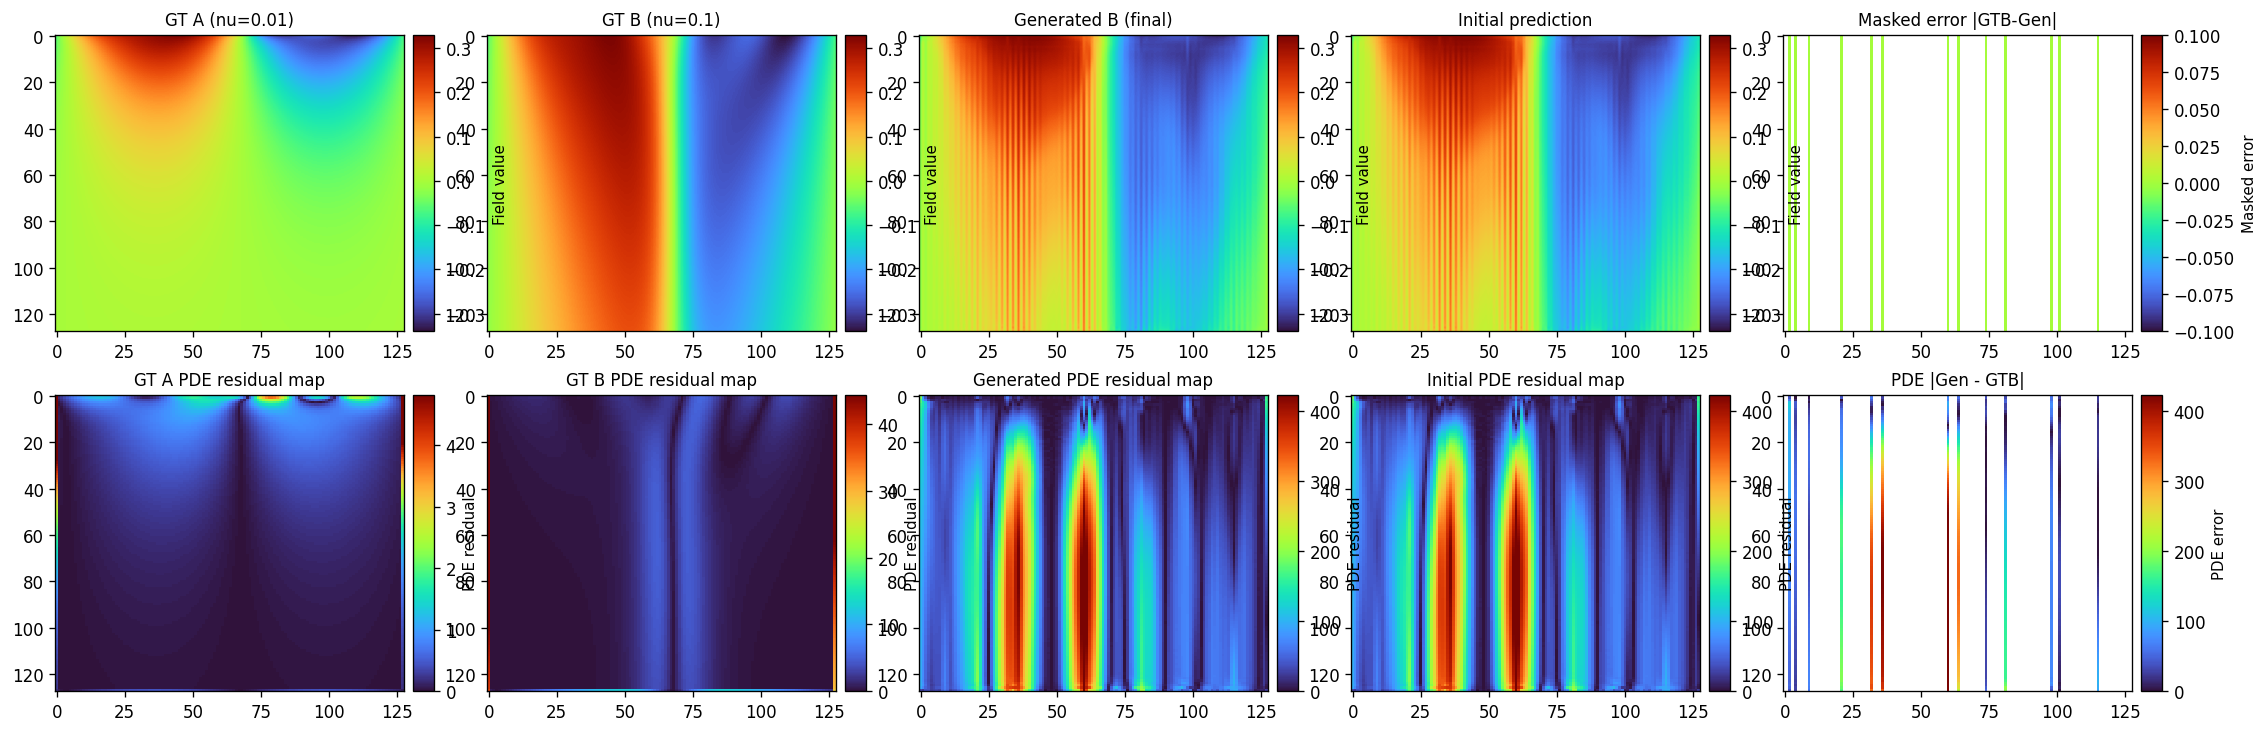

In [8]:
plot_result(
    dataA=x0_stitched,                       # low
    dataB=x1_stitched,                       # high
    dataB_predict_initial=pred_stitched,       # 없으면 predict[0]로 자동
    predict=pred_stitched,                 # eval_fore 결과(list)
    high_resol_coef=high_resol_coef,
    low_resol_coef=low_resol_coef,
    estimated_coef = sb_object.alpha.to('cpu'),
    mask_2d=m1_stitched                # (B,1,T,X)
)
